# Does any published model react correctly to a single substitution?

Peptide optimisation changes one residue at a time, so a stability oracle is only
useful if its output reacts to that change, if the reaction depends on which position
changed, and if the direction of the reaction matches measurements.

This notebook compares all artifacts on the three tests described in the per-model
notebooks, and states which of them could drive a search over single substitutions.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/model_benchmark").is_dir())
sys.path.insert(0, str(ROOT / "src"))

%matplotlib inline
import numpy as np
import pandas as pd
from IPython.display import display
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

In [2]:
from model_benchmark import report
from model_benchmark.config import PRIMARY_COHORT
from model_benchmark.dataset import load_cohort
from model_benchmark.pipeline import load_summaries
from model_benchmark.sensitivity import empirical_substitution_pairs

## REMARK: Only the published configurations carry a substitution analysis; the
## alternative-configuration runs were scored for accuracy alone.
summaries = load_summaries(published_only=True, cohort_name=PRIMARY_COHORT)
cohort = load_cohort(PRIMARY_COHORT)
noise_floor = float(cohort.loc[cohort.record_count > 1, "log10_spread"].median())
print(f"Artifacts: {len(summaries)}; measurement noise floor: {noise_floor:.3f} log10")

Artifacts: 9; measurement noise floor: 0.000 log10


## How much does one substitution move the prediction

The scan replaces every residue of a peptide by all 19 alternatives. The size of the
response must be compared with the measurement noise floor: a response far below it
cannot be resolved experimentally, and a response far above the measured effect size is
a different failure.

,Run,Configuration,Median |delta| substitution,Max |delta| substitution,Median |delta| permutation,Permutation / substitution,Positional variance share,Identical predictions,Gradient vs scan Spearman,Measured pairs,Sign agreement,Spearman of delta,Predicted / measured effect
0,peptiverse_transformer_chemberta,as published,0.0634,1.3996,0.1138,1.7961,0.2773,0.0000,nan,9,0.5556,-0.2333,0.1992
1,peptiverse_transformer_esm_log,as published,0.1012,0.7239,0.1180,1.1661,0.4568,0.0000,0.3833,9,0.6667,0.3000,0.1373
2,peptiverse_transformer_esm_raw,as published,0.1008,0.7915,0.1071,1.0628,0.3593,0.0000,0.3750,9,0.4444,-0.1167,0.2688
3,peptiverse_transformer_peptideclm,as published,0.0541,0.5402,0.0832,1.5394,0.3622,0.0000,nan,9,0.7778,0.5500,0.0755
4,peptiverse_xgb_chemberta,as published,0.0716,0.5792,0.0755,1.0538,0.2573,0.0000,nan,9,0.3333,0.5000,0.1074
5,peptiverse_xgb_esm_log,as published,0.0485,0.3240,0.0473,0.9751,0.2642,0.0000,nan,9,0.3333,-0.0667,0.1012
6,peptiverse_xgb_esm_raw,as published,0.0116,0.2239,0.0111,0.9571,0.1224,0.0000,nan,9,0.4444,0.0833,0.0146
7,peptiverse_xgb_peptideclm,as published,0.0252,0.3314,0.0314,1.2447,0.2113,0.1910,nan,9,0.4444,0.0667,0.0636
8,plifepred_svm,as published,0.3362,0.4500,0.0000,0.0000,0.2531,0.0000,nan,9,0.2222,-0.5000,0.0061


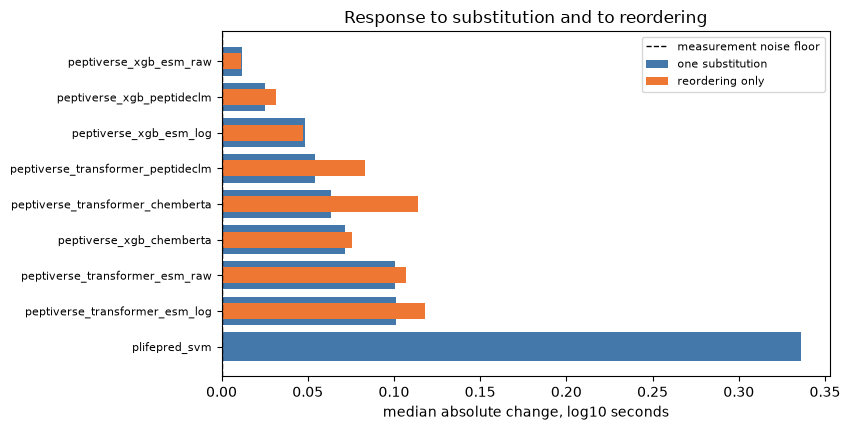

In [3]:
display(report.sensitivity_table(summaries).style.format(precision=4)
        .set_caption("Single-substitution response of every artifact"))

figure, axes = plt.subplots(figsize=(8.6, 4.4))
order = summaries.sort_values("scan_median_absolute_delta_log10", ascending=False)
positions = np.arange(len(order))
axes.barh(positions, order.scan_median_absolute_delta_log10, color="#4477AA", label="one substitution")
axes.barh(positions, order.permutation_median_absolute_delta_log10, height=0.45, color="#EE7733", label="reordering only")
axes.axvline(noise_floor, color="black", linestyle="--", linewidth=1.0, label="measurement noise floor")
axes.set_yticks(positions, order.predictor, fontsize=8)
axes.set_xlabel("median absolute change, log10 seconds")
axes.set_title("Response to substitution and to reordering")
axes.legend(fontsize=8)
figure.tight_layout()
display(figure)
plt.close("all")

## Positional structure

A composition-only representation still moves when a residue is replaced, but the move
barely depends on the position, and reordering the same residues changes nothing. The
positional variance share and the permutation ratio separate the two cases.

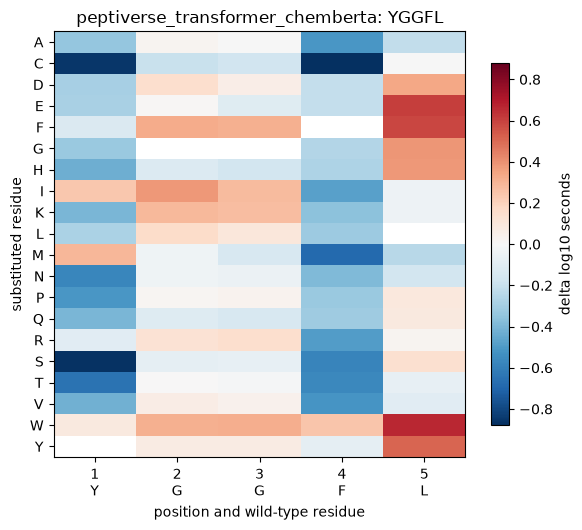

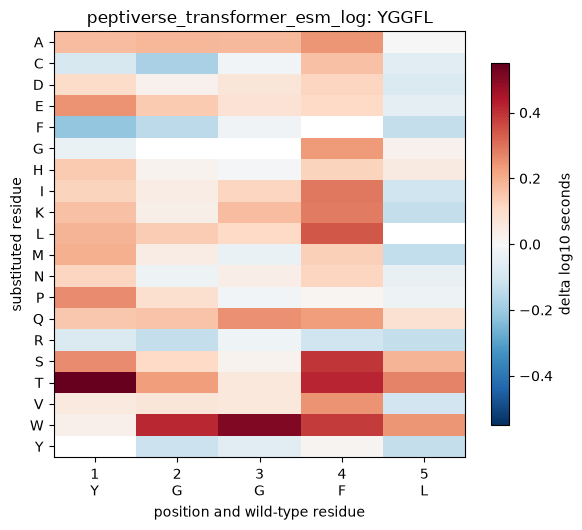

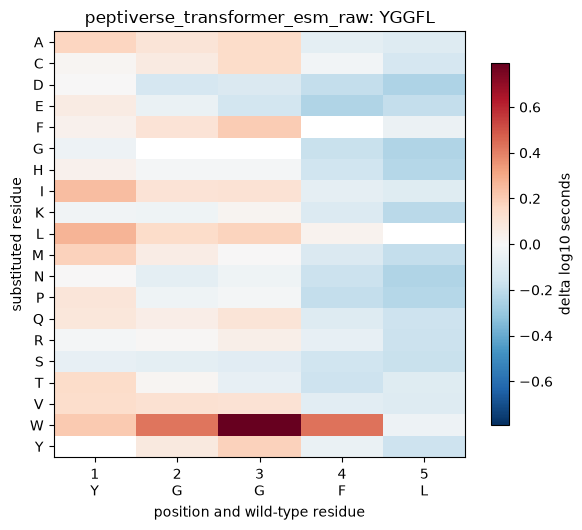

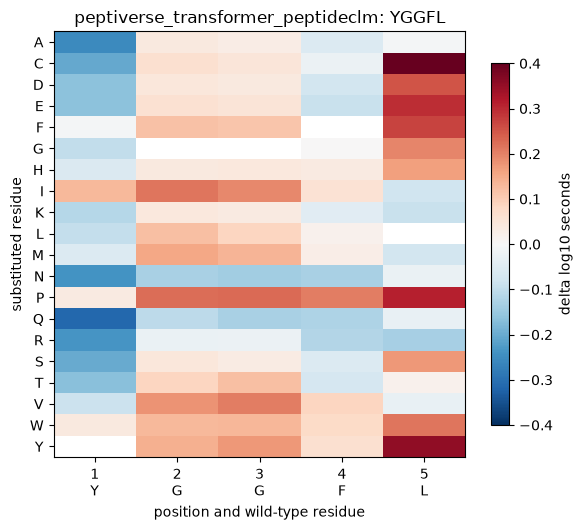

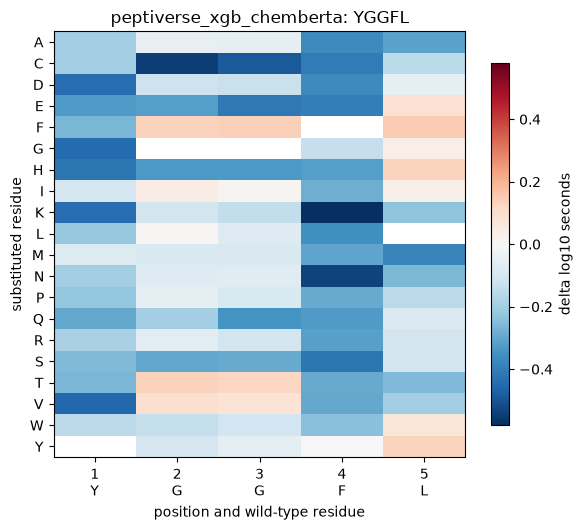

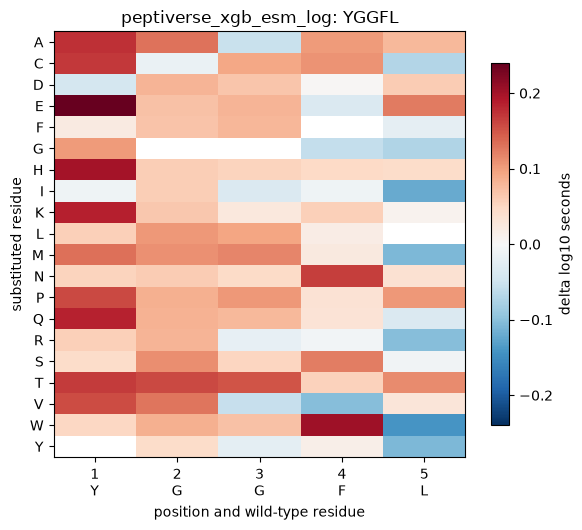

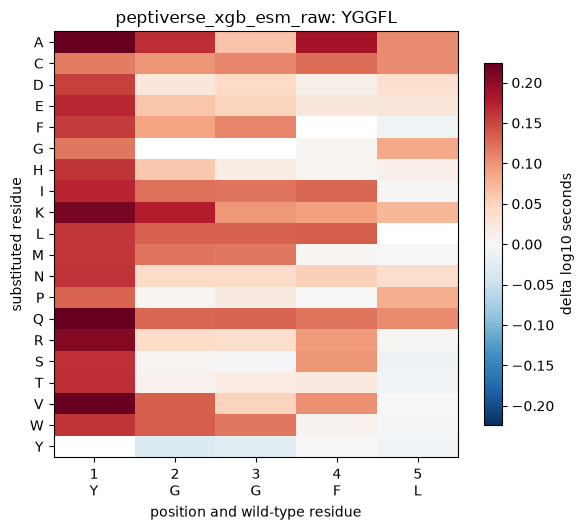

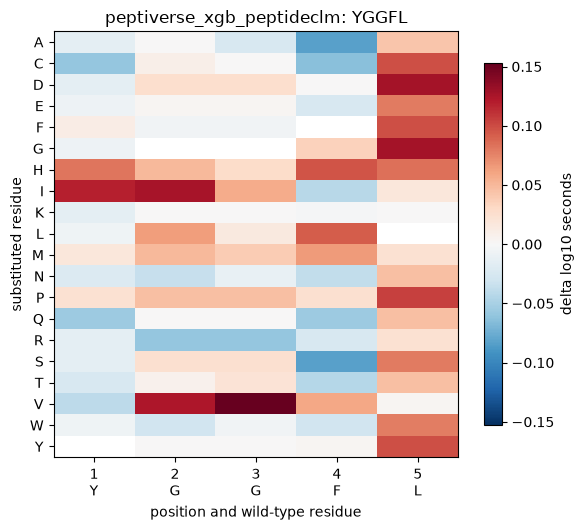

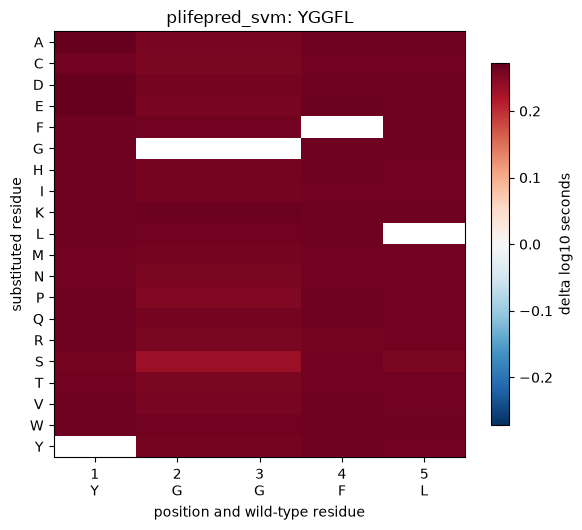

In [4]:
for run in summaries.run:
    scan = report.load_result(run, "mutational_scan.csv", PRIMARY_COHORT)
    if scan is None:
        continue
    parent = scan.parent.iloc[0]
    display(report.scan_heatmap(scan, parent=parent, title=f"{run}: {parent}"))
    plt.close("all")

## Gradients against finite differences

For the differentiable artifacts the input gradient should rank positions in the same
order as the exhaustive scan. Disagreement means a gradient-driven search would move in
a direction the model's own predictions do not support.

In [5]:
rows = []
for run in summaries.run:
    gradients = report.load_result(run, "gradient_agreement.csv", PRIMARY_COHORT)
    if gradients is None or "available" not in gradients:
        continue
    available = gradients.loc[gradients.available.fillna(False)]
    if available.empty:
        rows.append({"run": run, "available": False,
                     "reason": gradients.reason.iloc[0] if "reason" in gradients else "not differentiable"})
        continue
    rows.append({
        "run": run,
        "available": True,
        "median_spearman_gradient_vs_scan": float(available.spearman_gradient_vs_scan.median()),
        "median_nonzero_gradient_share": float(available.nonzero_gradient_share.median()),
    })
display(pd.DataFrame(rows).style.format(precision=3).set_caption("Input gradients against the exhaustive scan"))

,run,available,reason,median_spearman_gradient_vs_scan,median_nonzero_gradient_share
0,peptiverse_transformer_chemberta,False,gradient length 69 differs from scan length 5,nan,nan
1,peptiverse_transformer_esm_log,True,nan,0.383,1.000
2,peptiverse_transformer_esm_raw,True,nan,0.375,1.000
3,peptiverse_transformer_peptideclm,False,gradient length 30 differs from scan length 5,nan,nan
4,peptiverse_xgb_chemberta,False,peptiverse_xgb_chemberta is tree-based and has no input gradient,nan,nan
5,peptiverse_xgb_esm_log,False,peptiverse_xgb_esm_log is tree-based and has no input gradient,nan,nan
6,peptiverse_xgb_esm_raw,False,peptiverse_xgb_esm_raw is tree-based and has no input gradient,nan,nan
7,peptiverse_xgb_peptideclm,False,peptiverse_xgb_peptideclm is tree-based and has no input gradient,nan,nan
8,plifepred_svm,False,plifepred_svm does not expose input gradients,nan,nan


## Measured single substitutions

The empirical test. Pairs differ in exactly one residue and were measured under the same
condition, so their measured difference is comparable. The sample is small, which limits
what can be concluded: it can refute a model, not certify one.

Measured pairs available in the primary cohort: 12


,parent,variant,position,parent_residue,variant_residue,measured_delta_log10
0,ALAGIGILTV,DLAGIGILTV,0,A,D,0.019
1,ALAGIGILTV,ELAGIGILTV,0,A,E,-0.252
2,ALAGIGILTV,GLAGIGILTV,0,A,G,0.036
3,DLAGIGILTV,ELAGIGILTV,0,D,E,-0.271
4,DLAGIGILTV,GLAGIGILTV,0,D,G,0.017
5,EAAGIGILTV,ELAGIGILTV,1,A,L,1.084
6,ELAGIGILTV,GLAGIGILTV,0,E,G,0.288
7,GAAQAAGSGAAQAAG,GAAQAAGWGAAQAAG,7,S,W,0.145
8,GAAQAYGSGYAQAAG,GAAQAYGWGYAQAAG,7,S,W,0.512
9,GAARAAGSGAARAAG,GAARAAGWGAARAAG,7,S,W,-0.383


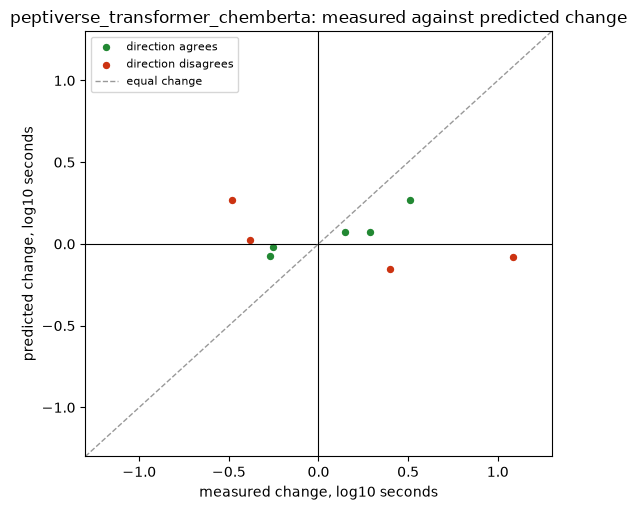

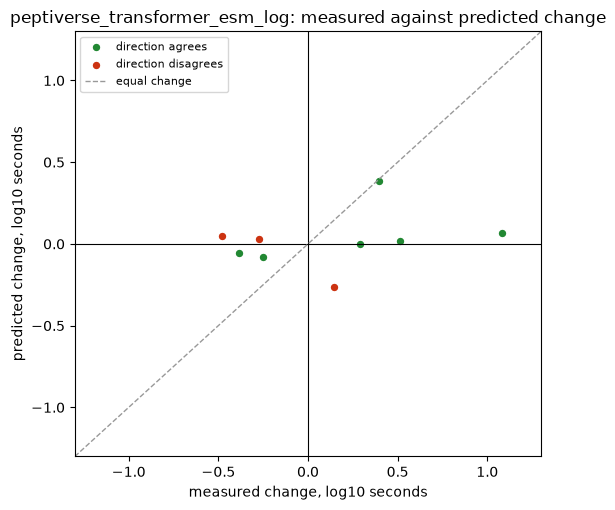

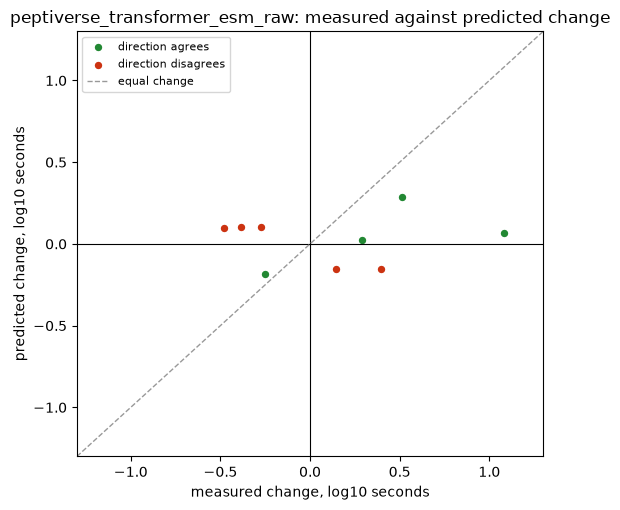

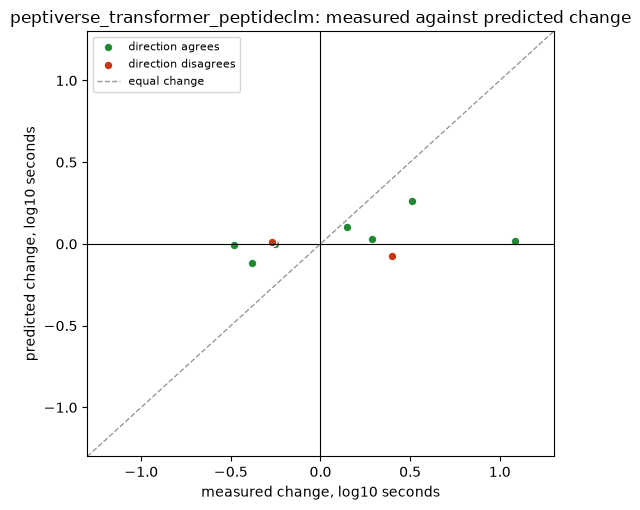

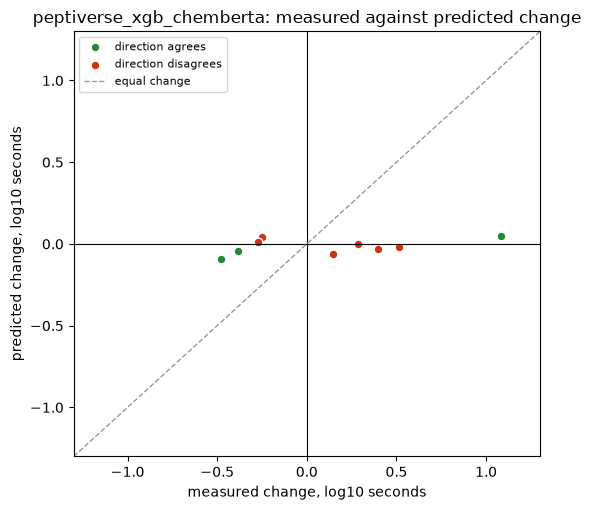

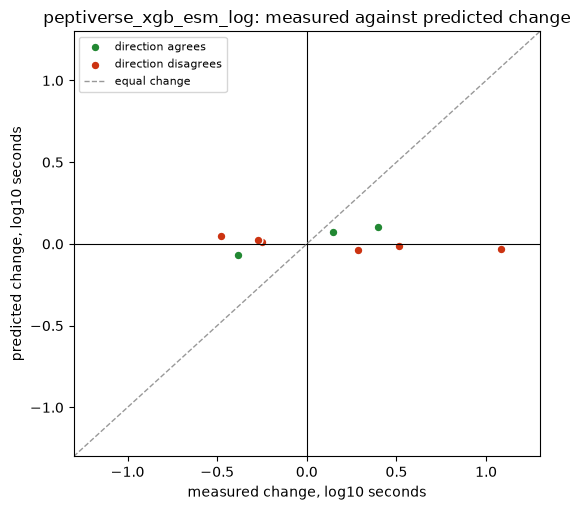

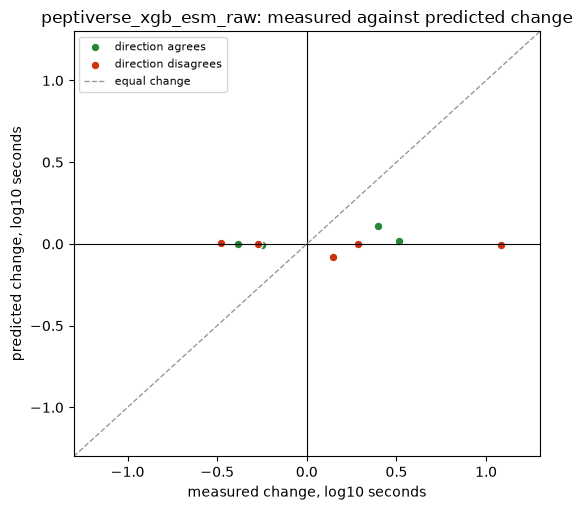

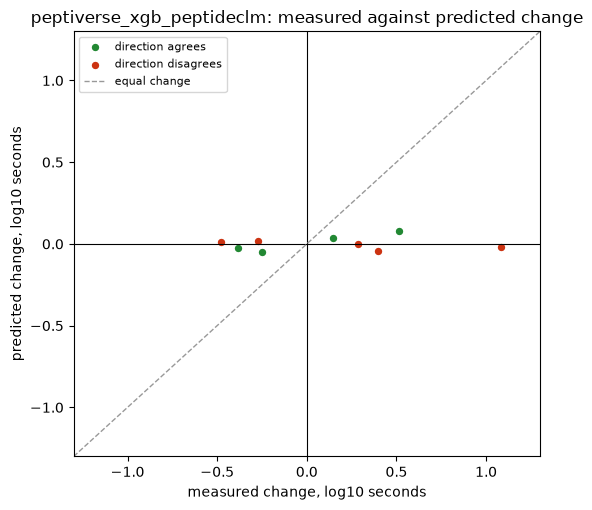

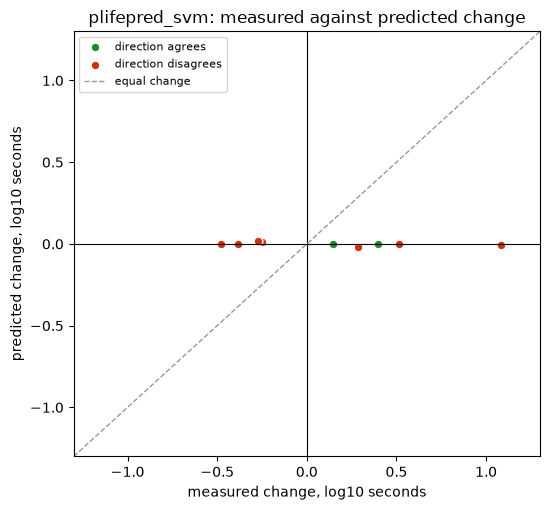

In [6]:
records = load_cohort(PRIMARY_COHORT, aggregate=False)
pairs = empirical_substitution_pairs(records)
print(f"Measured pairs available in the primary cohort: {len(pairs)}")
if not pairs.empty:
    display(pairs[["parent", "variant", "position", "parent_residue", "variant_residue", "measured_delta_log10"]]
            .style.format(precision=3).set_caption("Measured effect of one substitution"))

for run in summaries.run:
    scored = report.load_result(run, "measured_pairs.csv", PRIMARY_COHORT)
    if scored is None or not len(scored):
        continue
    display(report.measured_pairs_scatter(scored, title=f"{run}: measured against predicted change"))
    plt.close("all")

## What this means for optimisation in pep-compass

The statements below follow from the tables above.

In [7]:
for run in summaries.run:
    stored = report.load_result(run, "summary.json", PRIMARY_COHORT)
    lines = [line for line in report.verdict_lines(stored)
             if "substitution" in line or "Reordering" in line or "direction" in line]
    print(f"=== {run} ===")
    for line in lines:
        print("  -", line)
    print()

=== peptiverse_transformer_chemberta ===
  - Reacts to a single substitution with median |delta| 0.063 log10 (factor 1.16).
  - Reordering produces 1.80 of the substitution response, so residue order carries at least as much of the response as the identity of the replaced residue.
  - On 9 measured single-substitution pairs the predicted direction agrees 56% of the time.
  - Predicted substitution effects are 0.20 times the measured ones (measured median 0.38 log10).

=== peptiverse_transformer_esm_log ===
  - Reacts to a single substitution with median |delta| 0.101 log10 (factor 1.26).
  - Reordering produces 1.17 of the substitution response, so residue order carries at least as much of the response as the identity of the replaced residue.
  - On 9 measured single-substitution pairs the predicted direction agrees 67% of the time.
  - Predicted substitution effects are 0.14 times the measured ones (measured median 0.38 log10).

=== peptiverse_transformer_esm_raw ===
  - Reacts to a s